Audio Loaded Successfully
Sample Rate : 44100
Number of Samples : 5861953

Processing IR1
Output_IR1.wav saved successfully.


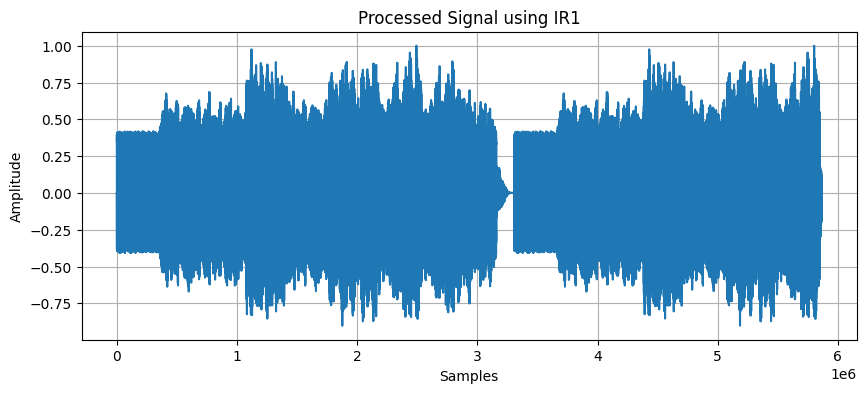


Processing IR2
Output_IR2.wav saved successfully.


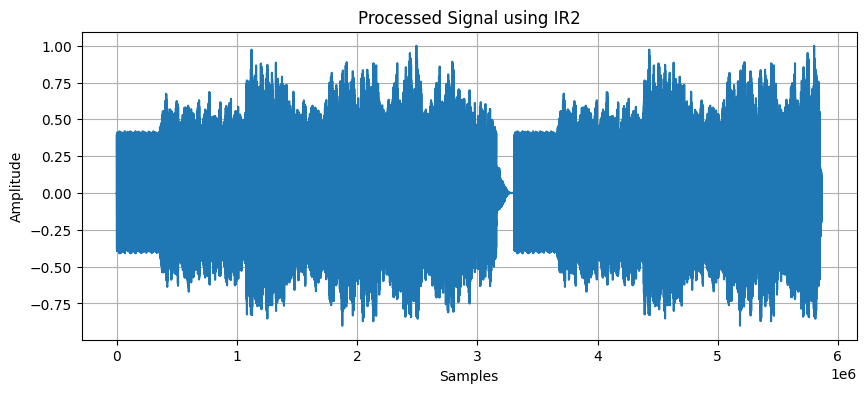


Processing IR3
Output_IR3.wav saved successfully.


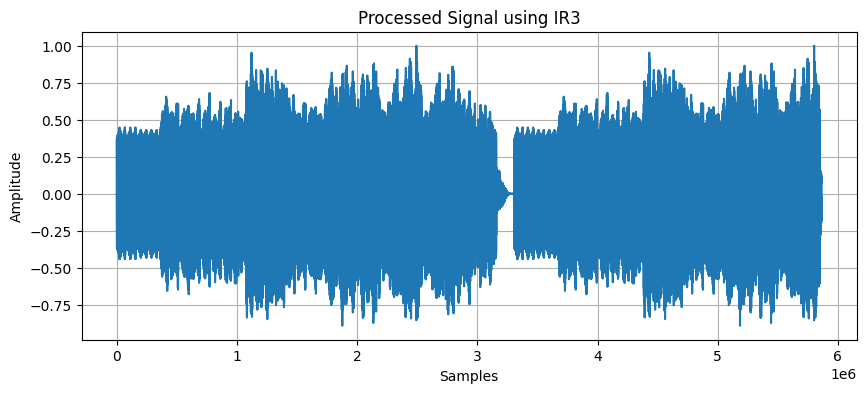


Processing IR4
Output_IR4.wav saved successfully.


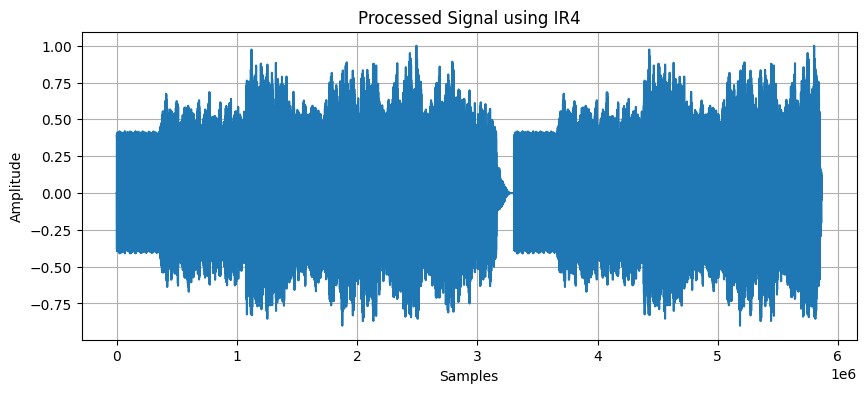


All files generated successfully.


In [ ]:
import librosa
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve

# Load Audio File

audio_file = "OPE2audio.mp3"

samples, sample_rate = librosa.load(audio_file, sr=None, mono=True)

print("Audio Loaded Successfully")
print("Sample Rate :", sample_rate)
print("Number of Samples :", len(samples))

# Different Impulse Responses

impulse_responses = {
    "IR1": np.array([1], dtype=float),
    "IR2": np.array([1, -0.5], dtype=float),
    "IR3": np.array([1, 0, -0.7], dtype=float),
    "IR4": np.array([1, -1, 1], dtype=float)
}

# Apply Convolution and Inverse Filtering

for name, h in impulse_responses.items():

    print("\nProcessing", name)

    # Convolution
    convoluted = convolve(samples, h, mode="same")

    # Create a simple inverse filter
    inverse_filter = np.zeros(len(h))
    inverse_filter[0] = 1

    for i in range(1, len(h)):
        inverse_filter[i] = -h[i]

    # Restore audio
    restored = convolve(convoluted, inverse_filter, mode="same")

    # Normalize audio
    restored = restored / np.max(np.abs(restored))

    # Save output
    output_name = "Output_" + name + ".wav"
    sf.write(output_name, restored, sample_rate)

    print(output_name, "saved successfully.")

    # Plot Signal
    plt.figure(figsize=(10,4))
    plt.plot(restored)
    plt.title("Processed Signal using " + name)
    plt.xlabel("Samples")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()

print("\nAll files generated successfully.")